# ⏱️ Notebook 6 — Gillespie Kinetic Monte Carlo
| | |
|---|---|
| ⏱ Time | ~30 min |
| 🎯 You will learn | the Gillespie recipe · rate constants → Monte Carlo rates · simulate a full **free-radical polymerization** in time |
| 🧰 Uses | Trick #3 (roulette wheel) + Trick #4 (waiting time) from Notebook 1 |
| 📖 Book algorithm | *Generic Gillespie Algorithm for Free Radical Polymerization* |

Notebooks 2–4 used **probabilities** (no time). Gillespie uses **rates** and gives you **conversion vs time**, radical concentration vs time, and MWD evolution — just like a reactor. The full table of rate conversions is in *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
random.seed(2)
plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True, "grid.alpha": 0.3})
trapz = getattr(np, "trapezoid", None) or np.trapz
NA = 6.022e23

## 1 · The Gillespie recipe (5 lines)
```
loop:
    compute the rate R_j of every reaction from the current molecule counts
    R_tot = Σ R_j
    pick reaction j with the roulette wheel          (Trick #3)
    do it (update the counts)
    t ← t + ln(1/Rnd) / R_tot                        (Trick #4)
```

### Warm-up: radioactive-style decay A → B
One reaction, rate `R = k · n_A`. Compare with the textbook `n_A(t) = n_A0 · e^(−kt)`.

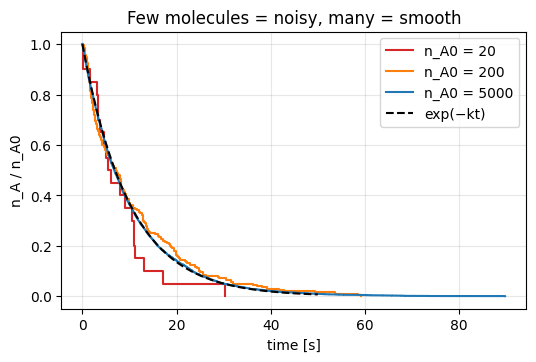

In [2]:
def decay(nA0, k):
    nA, t, ts, ns = nA0, 0.0, [0.0], [nA0]
    while nA > 0:
        R = k * nA
        t += np.log(1/random.random()) / R
        nA -= 1
        ts.append(t); ns.append(nA)
    return np.array(ts), np.array(ns)

k = 0.1
for nA0, c in [(20, "tab:red"), (200, "tab:orange"), (5000, "tab:blue")]:
    t, nA = decay(nA0, k)
    plt.step(t, nA/nA0, c=c, where="post", label=f"n_A0 = {nA0}")
tt = np.linspace(0, 50, 100)
plt.plot(tt, np.exp(-k*tt), "k--", label="exp(−kt)")
plt.xlabel("time [s]"); plt.ylabel("n_A / n_A0"); plt.legend(); plt.title("Few molecules = noisy, many = smooth"); plt.show()

## 2 · From lab rate constants to Monte Carlo rates
We simulate a tiny **control volume** `V`. Concentrations become molecule counts: `n = [C]·N_A·V`.

| reaction type | Monte Carlo rate constant | Monte Carlo rate |
|---|---|---|
| unimolecular (I → 2R) | `k_MC = k` | `k_MC · n_I` |
| bimolecular (P + M) | `k_MC = k / (N_A·V)` | `k_MC · n_P · n_M` |
| identical species (P + P) | `k_MC = k / (N_A·V)` | `k_MC · n_P · (n_P − 1)` |

⚠️ **Toy numbers ahead.** Real free-radical polymerization needs a *huge* `V` (≈10⁹–10¹⁰ monomer molecules) to hold even a few radicals. To run in seconds in Colab, we use made-up rate constants that keep the same **behaviour** with only 10⁵ monomers. The book discusses realistic sizes and speed-ups.

In [3]:
# ---- recipe (toy values) ----
M0, I0 = 1.0, 0.04          # mol/L
f, kd = 0.5, 0.02           # initiator efficiency, 1/s
ki = kp = 400.0             # L/(mol s)
kfm = 0.4                   # transfer to monomer, L/(mol s)
ktc, ktd = 5e3, 5e3         # combination, disproportionation, L/(mol s)
nM0 = 500_000               # monomer molecules in the control volume

V = nM0 / (M0 * NA)
bi = lambda k: k / (NA * V)                     # bimolecular MC constant
kMC = dict(kd=kd, ki=bi(ki), kp=bi(kp), kfm=bi(kfm), ktc=bi(ktc), ktd=bi(ktd))
nI0 = round(I0 * NA * V)
print(f"Control volume V = {V:.2e} L   →  n_M0 = {nM0:,},  n_I0 = {nI0:,}")

Control volume V = 8.30e-19 L   →  n_M0 = 500,000,  n_I0 = 20,000


## 3 · The free-radical polymerization simulation
Radicals are a Python list of chain lengths `P`; dead chains go into `dead`. Picking a random radical = picking a random index (all radicals react equally, whatever their length).

In [4]:
EVENTS = ["decomposition", "initiation", "propagation", "transfer", "combination", "disproportionation"]

def frp_gillespie(x_max=0.95, t_max=200, log_every=2000, verbose_first=0):
    nI, nR, nM = nI0, 0, nM0
    P, dead = [], []
    t, step = 0.0, 0
    hist = {"t": [], "x": [], "nP": [], "Mn": [], "PDI": []}
    s1 = s2 = 0                                    # running sums of dead lengths

    def take_random(lst):                          # remove & return a random element, O(1)
        k = random.randrange(len(lst)); val = lst[k]; lst[k] = lst[-1]; lst.pop(); return val

    while t < t_max and (nM0 - nM)/nM0 < x_max:
        nP = len(P)
        R = [kMC["kd"]*nI, kMC["ki"]*nR*nM, kMC["kp"]*nP*nM, kMC["kfm"]*nP*nM,
             kMC["ktc"]*nP*(nP-1), kMC["ktd"]*nP*(nP-1)]
        Rtot = sum(R)
        if Rtot == 0: break
        # roulette wheel
        r, j, acc = random.random()*Rtot, 0, R[0]
        while acc < r: j += 1; acc += R[j]
        # execute
        if j == 0:                                 # I → 2R (efficiency f)
            nI -= 1
            if random.random() <= f: nR += 2
        elif j == 1:                               # R + M → P1
            nR -= 1; nM -= 1; P.append(1)
        elif j == 2:                               # Pn + M → Pn+1
            k = random.randrange(nP); P[k] += 1; nM -= 1
        elif j == 3:                               # Pn + M → Dn + P1
            k = random.randrange(nP); dead.append(P[k]); s1 += P[k]; s2 += P[k]**2; P[k] = 1; nM -= 1
        elif j == 4:                               # Pn + Pm → D(n+m)
            L = take_random(P) + take_random(P); dead.append(L); s1 += L; s2 += L*L
        else:                                      # Pn + Pm → Dn + Dm
            for L in (take_random(P), take_random(P)): dead.append(L); s1 += L; s2 += L*L
        t += np.log(1/random.random()) / Rtot
        step += 1
        if step <= verbose_first:
            print(f"{step:3d}  t = {t:8.4f} s   {EVENTS[j]:<18s}  radicals = {len(P)}")
        if step % log_every == 0 and dead:
            hist["t"].append(t); hist["x"].append((nM0-nM)/nM0); hist["nP"].append(len(P))
            hist["Mn"].append(s1/len(dead)); hist["PDI"].append(s2*len(dead)/s1**2)
    return {k: np.array(v) for k, v in hist.items()}, np.array(dead), step

print("The first few events — notice decomposition must happen before anything else can:")
_ = frp_gillespie(x_max=1e-4, verbose_first=12)

The first few events — notice decomposition must happen before anything else can:
  1  t =   0.0014 s   decomposition       radicals = 0
  2  t =   0.0031 s   decomposition       radicals = 0
  3  t =   0.0032 s   decomposition       radicals = 0
  4  t =   0.0038 s   decomposition       radicals = 0
  5  t =   0.0039 s   initiation          radicals = 1
  6  t =   0.0040 s   decomposition       radicals = 1
  7  t =   0.0045 s   decomposition       radicals = 1
  8  t =   0.0049 s   decomposition       radicals = 1
  9  t =   0.0057 s   initiation          radicals = 2
 10  t =   0.0058 s   initiation          radicals = 3
 11  t =   0.0059 s   decomposition       radicals = 3
 12  t =   0.0062 s   propagation         radicals = 3


In [5]:
import time
t0 = time.time()
H, dead, steps = frp_gillespie()
print(f"{steps:,} events simulated in {time.time()-t0:.1f} s   |   dead chains: {len(dead):,}")

492,513 events simulated in 0.7 s   |   dead chains: 9,200


## 4 · ✅ Validation against the deterministic (ODE) model
For a big enough volume, the average Monte Carlo behaviour must match the classic rate equations.

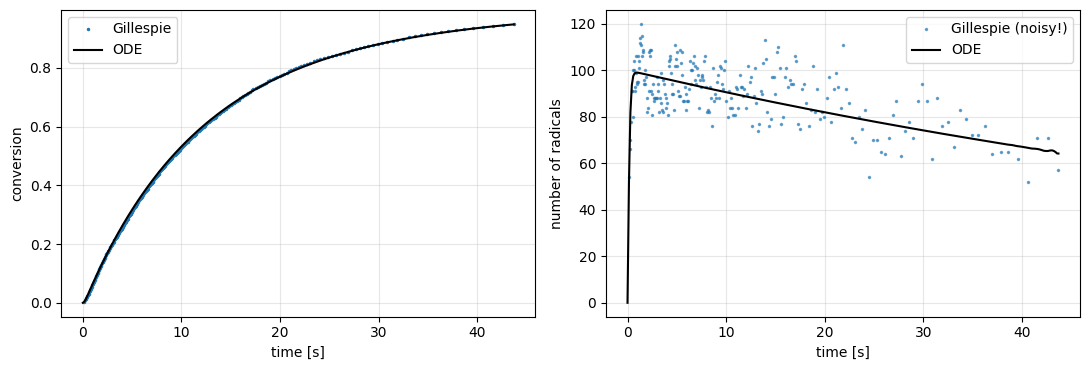

In [6]:
def odes(t, y):
    I, R, P, M = y
    return [-kd*I, 2*f*kd*I - ki*R*M, ki*R*M - 2*(ktc+ktd)*P**2, -ki*R*M - (kp+kfm)*P*M]

sol = solve_ivp(odes, [0, H["t"][-1]], [I0, 0, 0, M0], method="LSODA", dense_output=True, rtol=1e-8)
tt = np.linspace(0, H["t"][-1], 300); I, R, Pr, M = sol.sol(tt)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(H["t"], H["x"], ".", ms=3, label="Gillespie"); ax[0].plot(tt, 1 - M/M0, "k-", label="ODE")
ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("conversion"); ax[0].legend()
ax[1].plot(H["t"], H["nP"], ".", ms=3, alpha=0.6, label="Gillespie (noisy!)"); ax[1].plot(tt, Pr*NA*V, "k-", label="ODE")
ax[1].set_xlabel("time [s]"); ax[1].set_ylabel("number of radicals"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5 · What the ODE *can't* easily give you: the full MWD
Monte Carlo keeps every chain → averages *and* the complete distribution, at any time.

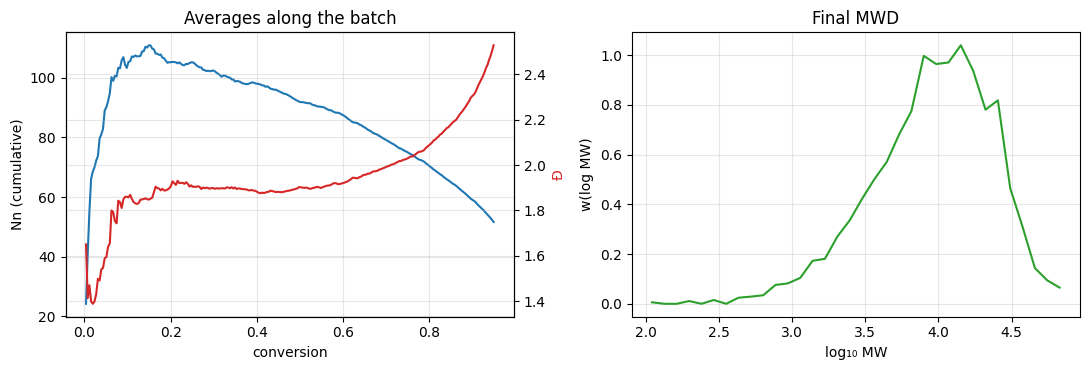

In [7]:
edges = np.logspace(0, np.log10(dead.max()+1), 35)
h, _ = np.histogram(dead, bins=edges, weights=dead)
x = np.log10(np.sqrt(edges[1:]*edges[:-1]) * 100.12)    # MMA-like repeat unit
y = h/np.diff(np.log10(edges)); y /= trapz(y, x)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(H["x"], H["Mn"], label="Nn"); ax2 = ax[0].twinx(); ax2.plot(H["x"], H["PDI"], c="tab:red", label="Đ")
ax[0].set_xlabel("conversion"); ax[0].set_ylabel("Nn (cumulative)"); ax2.set_ylabel("Đ", color="tab:red")
ax[0].set_title("Averages along the batch")
ax[1].plot(x, y, c="tab:green"); ax[1].set_xlabel("log₁₀ MW"); ax[1].set_ylabel("w(log MW)")
ax[1].set_title("Final MWD")
plt.tight_layout(); plt.show()

## ✅ Recap
- Gillespie = **rates → roulette wheel → do it → advance the clock**.
- Bimolecular rate constants are divided by `N_A·V`; the control volume sets how many molecules you simulate.
- Same answer as the ODE *on average*, plus noise and full chain-level detail.

### 🧪 Try it yourself
1. Set `ktd = 0` (only combination). What happens to Đ?
2. Raise `kfm` ten-fold. Which curve changes: conversion, Nn, or both?
3. Halve `nM0`. How do the noise and the run time change?

➡️ **Next: Notebook 7 — Gillespie minis: ATRP & polymer degradation**